---
downloads:
  - file: tp01_coordonnees_cylindriques_cartesiennes_teacher.ipynb
    title: Notebook enseignant
    filename: tp01_coordonnees_cylindriques_cartesiennes_enseignant.ipynb
  - file: ../notebooks_student/tp01_coordonnees_cylindriques_cartesiennes_student.ipynb
    title: Notebook étudiant
    filename: tp01_coordonnees_cylindriques_cartesiennes_etudiant.ipynb
---


# TP 01 — Cinématique du point matériel : Système de coordonnées

Dans ce TP, nous étudions comment repérer un point matériel dans l'espace à l'aide de différents systèmes de coordonnées. Nous verrons également comment passer de l'un à l'autre.

:::{important} Versions enseignant.
Cette page présente la version **corrigée**, destinée aux enseignants.

Pour télécharger la version à distribuer aux étudiants et à déposer sur
Boostcamp, utilisez le bouton **Notebook étudiant** dans le menu de
téléchargement situé en haut de la page.

Les liens suivants ouvrent les notebooks dans Google Colab :

- [Notebook enseignant](https://colab.research.google.com/github/ECE-Ecole-Ingenieurs/cours-physique/blob/main/notebooks/tp01_coordonnees_cylindriques_cartesiennes_teacher.ipynb) ;
- [Notebook étudiant](https://colab.research.google.com/github/ECE-Ecole-Ingenieurs/cours-physique/blob/main/notebooks_student/tp01_coordonnees_cylindriques_cartesiennes_student.ipynb).
:::

**Importation bibliothèques**

In [1]:
import numpy as np  # Manipulation des vecteurs et opérations matricielles
import matplotlib.pyplot as plt  # Tracé des figures 2D et 3D

## 1. Rappel de cours

En mécanique du point matériel, on modélise un objet par un point $M$, repéré par le vecteur position $\overrightarrow{OM}$, où $O$ est l'origine du repère.

**Coordonnées cartésiennes** : le point est décrit par $M = (x, y, z)$, dans la base $(\overrightarrow{e_x}, \overrightarrow{e_y}, \overrightarrow{e_z})$ :

$$
\overrightarrow{OM} = x\,\overrightarrow{e_x} + y\,\overrightarrow{e_y} + z\,\overrightarrow{e_z}
$$

**Coordonnées cylindriques** : le même point est décrit par $M = (r, \theta, z)$, dans la base $(\overrightarrow{e_r}, \overrightarrow{e_\theta}, \overrightarrow{e_z})$ :

$$
\overrightarrow{OM} = r\,\overrightarrow{e_r} + z\,\overrightarrow{e_z}
$$

où :

- $r$ est la distance du point à l'axe vertical $z$ ;
- $\theta$ est l'angle dans le plan horizontal $(x, y)$ ;
- $z$ est la hauteur du point.

## 2. Projection d'un vecteur dans la base cartésienne

Le point matériel est repéré par un unique vecteur $\overrightarrow{OM}$. Dans
la base cartésienne fixe, ses coordonnées sont les composantes de ce vecteur :

$$
\overrightarrow{OM} = x\,\overrightarrow{e_x} + y\,\overrightarrow{e_y} + z\,\overrightarrow{e_z}
$$

Les coordonnées $(x,y,z)$ indiquent combien $\overrightarrow{OM}$ avance dans
chaque direction de cette base. La figure montre la construction successive
de ces trois composantes.



### 2.1 Théorie

:::{admonition} ✍️ Questions
:class: tip

1. Comment obtient-on la composante $x$ du vecteur $\overrightarrow{OM}$ à partir de $\overrightarrow{OM}$ et de $\overrightarrow{e_x}$ ? Rappelez la définition du produit scalaire entre deux vecteurs.
2. Exprimez de la même façon les composantes $y$ et $z$.
3. Que vaut $\overrightarrow{e_x}\cdot\overrightarrow{e_y}$ ? Pourquoi est-ce nécessaire pour que cette méthode fonctionne ?
:::

:::{admonition} Réponses
:class: note

1. La composante $x$ s'obtient par le produit scalaire
   $x=\overrightarrow{OM}\cdot\overrightarrow{e_x}$.
2. De la même façon, $y=\overrightarrow{OM}\cdot\overrightarrow{e_y}$ et
   $z=\overrightarrow{OM}\cdot\overrightarrow{e_z}$.
3. $\overrightarrow{e_x}\cdot\overrightarrow{e_y}=0$ : la base est
   orthonormée. C'est indispensable, sinon chaque produit scalaire
   mélangerait les contributions des autres composantes.
:::

### 2.2 Implémentation numérique

:::{admonition} 💻 Code
:class: tip

Complétez la fonction `projection_cartesienne` qui, à partir du vecteur
position $\overrightarrow{OM}$ (un tableau NumPy `[x, y, z]`, voir le
type indiqué dans la signature), renvoie ses trois composantes en
calculant le produit scalaire avec les vecteurs de la base cartésienne
$\overrightarrow{e_x}$, $\overrightarrow{e_y}$ et $\overrightarrow{e_z}$.
:::

In [ ]:
def projection_cartesienne(OM: np.ndarray):
    """
    Calcule les composantes cartésiennes de OM par produit scalaire avec les
    vecteurs de la base.

    Paramètres
    ----------
    OM : np.ndarray
        Vecteur position [x, y, z] [m].

    Renvoie
    -------
    x, y, z : float
        Composantes cartésiennes de OM [m].
    """
    e_x = np.array([1.0, 0.0, 0.0])
    e_y = np.array([0.0, 1.0, 0.0])
    e_z = np.array([0.0, 0.0, 1.0])

    x = np.dot(OM, e_x)
    y = np.dot(OM, e_y)
    z = np.dot(OM, e_z)

    return x, y, z

### 2.3 Analyse

Le code suivant représente un point matériel $M$ de coordonnées cartésiennes
$x=3{,}0~\mathrm{m}$, $y=3{,}0~\mathrm{m}$ et $z=3{,}5~\mathrm{m}$.
Utilisez les curseurs pour modifier les composantes de son vecteur position.

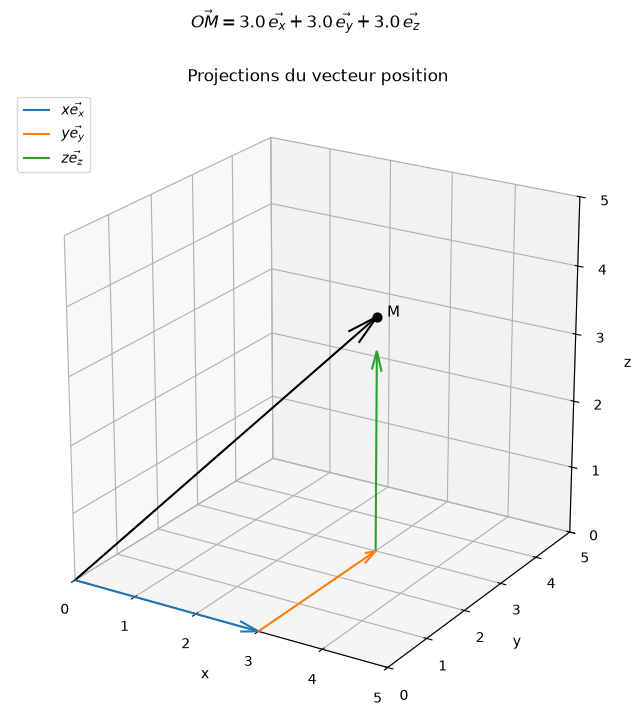

In [14]:
def afficher_projections(x, y, z):
    """Trace le vecteur position OM et ses projections sur les trois axes cartésiens."""
    OM = np.array([x, y, z])
    x_proj, y_proj, z_proj = projection_cartesienne(OM)

    fig, ax = plt.subplots(figsize=(10, 8),subplot_kw={"projection": "3d"})

    ax.quiver(0, 0, 0, *OM, color="black", arrow_length_ratio=0.08)
    ax.scatter(*OM, color="black", s=40)
    ax.text(*OM, "  M", fontsize=11)

    # Composantes calculées par projection_cartesienne
    ax.quiver(0, 0, 0, x_proj, 0, 0, color="tab:blue", arrow_length_ratio=0.1, label=r"$x\vec{e_x}$")
    ax.quiver(x_proj, 0, 0, 0, y_proj, 0, color="tab:orange", arrow_length_ratio=0.1, label=r"$y\vec{e_y}$")
    ax.quiver(x_proj, y_proj, 0, 0, 0, z_proj, color="tab:green", arrow_length_ratio=0.1, label=r"$z\vec{e_z}$")

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
    ax.set_xlim(0, 5)
    ax.set_ylim(0, 5)
    ax.set_zlim(0, 5)
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=22, azim=-58)
    ax.legend(loc="upper left")
    ax.set_title("Projections du vecteur position")
    fig.suptitle(
        rf"$\vec{{OM}} = {x_proj:.1f}\,\vec{{e_x}} + {y_proj:.1f}\,\vec{{e_y}} + {z_proj:.1f}\,\vec{{e_z}}$",
        y=0.98,
    )

    plt.show()
    plt.close(fig)

afficher_projections(3.0, 3.0, 3.5)

In [4]:
from ipywidgets import interact, FloatSlider

interact(
    afficher_projections,
    x=FloatSlider(value=3.0, min=0.0, max=5.0, step=0.5),
    y=FloatSlider(value=3.0, min=0.0, max=5.0, step=0.5),
    z=FloatSlider(value=3.5, min=0.0, max=5.0, step=0.5),
);

interactive(children=(FloatSlider(value=3.0, description='x', max=5.0, step=0.5), FloatSlider(value=3.0, descr…

:::{admonition} 🔍 Exploration
:class: tip

1. Que devient la construction lorsque l'une des composantes est nulle ?
2. Que devient la construction lorsque deux composantes sont nulles ?
3. Que devient le vecteur $\overrightarrow{OM}$ lorsque toutes ses composantes
   sont nulles ?
4. Quelles sont les projections de $\overrightarrow{OM}$ sur les axes $Ox$,
   $Oy$ et $Oz$ ?
:::

:::{admonition} Réponses
:class: note

1. Si une composante est nulle, le vecteur $\overrightarrow{OM}$ appartient au
   plan défini par les deux autres axes.
2. Si deux composantes sont nulles, $\overrightarrow{OM}$ est porté par l'axe
   associé à la composante restante.
3. Si toutes ses composantes sont nulles, $\overrightarrow{OM}=\overrightarrow{0}$
   et le point $M$ est confondu avec l'origine $O$, c'est le vecteur nul!
4. Les projections scalaires sur $Ox$, $Oy$ et $Oz$ valent respectivement
   $x$, $y$ et $z$. Les composantes vectorielles correspondantes sont
   $x\,\overrightarrow{e_x}$, $y\,\overrightarrow{e_y}$ et
   $z\,\overrightarrow{e_z}$.
:::

:::{important}
Pour afficher la version interactive, ouvrez le **Notebook enseignant** en
local ou ouvrez ce notebook dans Google Colab.
:::

## 3. Changement de base : base polaire → base cartésienne

Contrairement aux vecteurs de la base cartésienne, les vecteurs de la base
polaire $(\overrightarrow{e_r}, \overrightarrow{e_\theta})$ ne sont pas
fixes : ils dépendent de l'angle $\theta$ et tournent avec le point $M$. Pour
les manipuler avec les mêmes outils que la base cartésienne — somme, produit
scalaire, tracé — nous devons d'abord les exprimer dans la base
$(\overrightarrow{e_x}, \overrightarrow{e_y})$.

### 3.1 Théorie

:::{admonition} ✍️ Questions
:class: tip

Exprimez les vecteurs $\overrightarrow{e_r}(\theta)$ et
$\overrightarrow{e_\theta}(\theta)$ de la base polaire dans la base
cartésienne $(\overrightarrow{e_x}, \overrightarrow{e_y})$.
:::

:::{admonition} Aide
:class: hint

- Sur un cercle trigonométrique, le vecteur unitaire porté par la direction
  radiale à l'angle $\theta$ a pour coordonnées $(\cos\theta, \sin\theta)$.
- $\overrightarrow{e_\theta}$ est orthogonal à $\overrightarrow{e_r}$ et
  pointe dans le sens des $\theta$ croissants : il s'obtient en tournant
  $\overrightarrow{e_r}$ de $+90°$. Une rotation de $+90°$ transforme
  $(u_x, u_y)$ en $(-u_y, u_x)$.
:::

:::{admonition} Réponses
:class: note

$$
\overrightarrow{e_r} = \cos\theta\,\overrightarrow{e_x} + \sin\theta\,\overrightarrow{e_y}
\qquad
\overrightarrow{e_\theta} = -\sin\theta\,\overrightarrow{e_x} + \cos\theta\,\overrightarrow{e_y}
$$
:::

:::{admonition} Appelez le professeur
:class: warning

Avant de passer à l'implémentation, faites valider votre raisonnement par
l'enseignant.
:::

### 3.2 Implémentation numérique

:::{admonition} 💻 Code
:class: tip

Complétez la fonction `base_polaire` qui renvoie les vecteurs
$\overrightarrow{e_r}$ et $\overrightarrow{e_\theta}$ exprimés dans la base
cartésienne pour un angle $\theta$ donné.
:::

In [5]:
def base_polaire(theta):
    '''
    Exprime les vecteurs de la base polaire e_r et e_theta dans la base
    cartésienne, pour un angle theta donné.

    Paramètres
    ----------
    theta : float
        Coordonnée angulaire [rad].

    Renvoie
    -------
    e_r, e_theta : np.ndarray
        Vecteurs de base exprimés dans la base cartésienne (2D, dans le plan xy).
    '''

    # Vecteur de base radial
    e_r = np.array([np.cos(theta), np.sin(theta)])

    # Vecteur de base orthoradial
    e_theta = np.array([-np.sin(theta), np.cos(theta)])

    return e_r, e_theta

Le code suivant permet de vérifier que votre implémentation définit bien une base orthonormée. Que signifie cette propriété ?

In [6]:
# Vérification : la base polaire doit être orthonormée
theta_test = np.radians(35)
e_r, e_theta = base_polaire(theta_test)

print("e_r . e_r =", np.dot(e_r, e_r), "(attendu : 1)")
print("e_theta . e_theta =", np.dot(e_theta, e_theta), "(attendu : 1)")
print("e_r . e_theta =", np.dot(e_r, e_theta), "(attendu : 0)")

e_r . e_r = 0.9999999999999999 (attendu : 1)
e_theta . e_theta = 0.9999999999999999 (attendu : 1)
e_r . e_theta = 0.0 (attendu : 0)


### 3.3 Analyse

Le code suivant représente la base cartésienne fixe et la base polaire
pour $\theta=35^\circ$. Exécutez-le, puis faites varier $\theta$ afin
d'observer le mouvement des vecteurs de la base polaire.

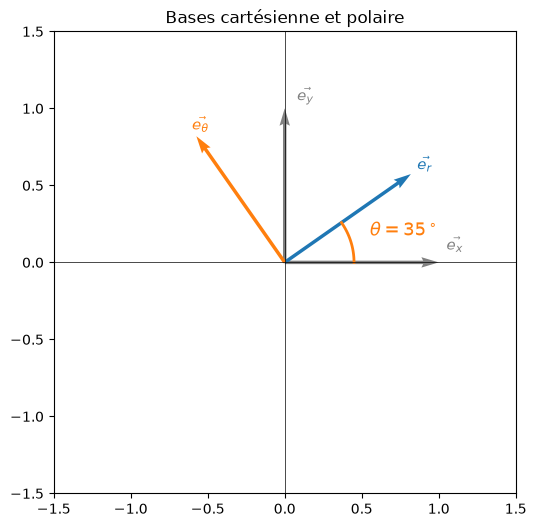

In [7]:
def afficher_base_polaire(theta_degrees):
    """Trace la base cartésienne fixe et la base polaire tournée pour un angle theta donné."""
    theta = np.radians(theta_degrees)
    e_r, e_theta = base_polaire(theta)

    fig, ax = plt.subplots(figsize=(6, 6))

    # Base cartésienne fixe
    ax.quiver(0, 0, 1, 0, color='grey', angles='xy', scale_units='xy', scale=1)
    ax.quiver(0, 0, 0, 1, color='grey', angles='xy', scale_units='xy', scale=1)
    ax.text(1.05, 0.08, r"$\vec{e_x}$", fontsize=11, color='grey')
    ax.text(0.08, 1.05, r"$\vec{e_y}$", fontsize=11, color='grey')

    # Base polaire mobile
    ax.quiver(0, 0, *e_r, color='tab:blue', angles='xy', scale_units='xy', scale=1)
    ax.quiver(0, 0, *e_theta, color='tab:orange', angles='xy', scale_units='xy', scale=1)
    ax.text(*(1.05*e_r), r"$\vec{e_r}$", fontsize=11, color='tab:blue')
    ax.text(*(1.05*e_theta), r"$\vec{e_\theta}$", fontsize=11, color='tab:orange')

    # Angle theta entre l'axe x et le vecteur radial
    arc_radius = 0.45
    angle_values = np.linspace(0.0, theta, 100)
    ax.plot( arc_radius * np.cos(angle_values),arc_radius * np.sin(angle_values), color='tab:orange',linewidth=2)
    label_angle = theta / 2 if theta != 0 else 0.12
    ax.text( 0.58 * np.cos(label_angle), 0.58 * np.sin(label_angle), rf"$\theta = {theta_degrees:.0f}^\circ$", color='tab:orange', fontsize=13)

    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_aspect('equal')
    ax.axhline(0, color='black', linewidth=0.5)
    ax.axvline(0, color='black', linewidth=0.5)
    ax.set_title("Bases cartésienne et polaire")
    plt.show()
    plt.close(fig)

afficher_base_polaire(35)

In [8]:
from ipywidgets import interact, IntSlider

interact(
    afficher_base_polaire,
    theta_degrees=IntSlider(value=35, min=-360, max=360, step=5, description='θ (°)'),
);

interactive(children=(IntSlider(value=35, description='θ (°)', max=360, min=-360, step=5), Output()), _dom_cla…

:::{admonition} 🔍 Exploration
:class: tip

1. Que se passe-t-il pour $\overrightarrow{e_r}$ et
   $\overrightarrow{e_\theta}$ lorsque $\theta$ varie ?
2. Que retrouvez-vous lorsque $\theta$ augmente de $360^\circ$ ?
3. Quelle base reste fixe ? Quelle conséquence la rotation de la base
   polaire peut-elle avoir sur le calcul de la vitesse ?
4. Les produits scalaires vérifiés ci-dessus restent-ils valables quel
   que soit $\theta$ ? Qu'est-ce que cela signifie pour la base
   polaire ?
:::

:::{admonition} Réponses
:class: note

1. Les deux vecteurs tournent avec $\theta$ tout en restant unitaires et
   orthogonaux.
2. Après une rotation de $360^\circ$, ils retrouvent leur orientation initiale.
3. La base cartésienne reste fixe. Comme la base polaire tourne, ses
   vecteurs dépendent du temps lorsque $\theta=\theta(t)$ ; leur dérivée doit
   donc être prise en compte dans le calcul de la vitesse.
4. Oui : une rotation conserve les normes et les angles, donc
   $\overrightarrow{e_r}$ et $\overrightarrow{e_\theta}$ restent une base
   orthonormée quel que soit $\theta$.
:::

:::{important}
Pour afficher la version interactive, ouvrez le **Notebook enseignant** en
local ou ouvrez ce notebook dans Google Colab.
:::

## 4. Passage des coordonnées cylindriques aux coordonnées cartésiennes

On définit un point matériel $M$ par ses coordonnées cylindriques :

$$
r = 3~\mathrm{m}, \qquad \theta = 35^\circ, \qquad z = 4~\mathrm{m}
$$

Nous cherchons à exprimer les coordonnées cartésiennes $(x,y,z)$ de ce
même point, en nous appuyant sur le changement de base établi à la
section 3.

### 4.1 Théorie

:::{admonition} ✍️ Questions
:class: tip

En utilisant l'expression de $\overrightarrow{e_r}$ obtenue à la
section 3, exprimez le vecteur position
$\overrightarrow{OM}=r\overrightarrow{e_r}+z\overrightarrow{e_z}$ dans
la base cartésienne, puis identifiez les coordonnées $x$, $y$ et $z$
correspondantes.
:::

:::{admonition} Aide
:class: hint

Remplacez $\overrightarrow{e_r}$ par son expression dans la base
cartésienne, puis identifiez les coefficients de $\overrightarrow{e_x}$
et $\overrightarrow{e_y}$ dans
$\overrightarrow{OM}=r\overrightarrow{e_r}+z\overrightarrow{e_z}$.
:::

:::{admonition} Réponses
:class: note

$$
\overrightarrow{OM}
= r\left(\cos\theta\,\overrightarrow{e_x}+\sin\theta\,\overrightarrow{e_y}\right)+z\,\overrightarrow{e_z}
= \underbrace{r\cos\theta}_{x}\,\overrightarrow{e_x}+\underbrace{r\sin\theta}_{y}\,\overrightarrow{e_y}+z\,\overrightarrow{e_z}
$$

d'où $x=r\cos\theta$, $y=r\sin\theta$, et $z$ reste inchangée. Ces
relations ne sont pas des formules à apprendre par cœur, mais une
conséquence directe du changement de base.
:::

:::{admonition} Appelez le professeur
:class: warning

Avant de passer à l'implémentation, faites valider votre raisonnement par
l'enseignant.
:::

### 4.2 Implémentation numérique

:::{attention} Attention aux unités
En Python, les fonctions `np.sin` et `np.cos` utilisent des angles en radians.

Si l'angle est donné en degrés, il faut le convertir avec :

```python
theta = np.radians(theta_degrees)
```
:::

In [9]:
# Coordonnées cylindriques du point matériel M
r = 3.0                    # radial distance [m]
theta_degrees = 35.0       # angle [deg]
z = 4.0                    # height [m]

# Les fonctions trigonométriques de NumPy utilisent des radians
theta = np.radians(theta_degrees)

print("Cylindrical coordinates")
print(f"r = {r:.3f} m")
print(f"theta = {theta_degrees:.3f} deg = {theta:.3f} rad")
print(f"z = {z:.3f} m")

Cylindrical coordinates
r = 3.000 m
theta = 35.000 deg = 0.611 rad
z = 4.000 m


:::{admonition} 💻 Code
:class: tip

Écrivez la fonction `cylindrical_to_cartesian` qui prend en entrée les
coordonnées cylindriques $(r,\theta,z)$ d'un point matériel et renvoie ses
coordonnées cartésiennes $(x,y,z)$.
:::

In [10]:
def cylindrical_to_cartesian(r, theta, z):
    '''
    Convertit des coordonnées cylindriques en coordonnées cartésiennes.

    Paramètres
    ----------
    r : float
        Distance radiale à l'axe Oz [m].
    theta : float
        Coordonnée angulaire dans le plan xy [rad].
    z : float
        Coordonnée verticale [m].

    Renvoie
    -------
    x : float
        Coordonnée cartésienne selon x [m].
    y : float
        Coordonnée cartésienne selon y [m].
    z_cart : float
        Coordonnée cartésienne selon z [m].
    '''

    # Projection de la distance radiale sur l'axe x
    x = r * np.cos(theta)

    # Projection de la distance radiale sur l'axe y
    y = r * np.sin(theta)

    # La coordonnée verticale est inchangée
    z_cart = z

    return x, y, z_cart

### 4.3 Analyse

Le code suivant applique la fonction de conversion et représente le point
$M(r,\theta,z)=(3~\mathrm{m},35^\circ,4~\mathrm{m})$ dans l'espace.
Exécutez-le, puis faites varier $r$, $\theta$ et $z$ dans la version
interactive.

La figure montre deux manières de lire la position du point :

- un repère cartésien, représenté par un cube de lecture ;
- une description cylindrique, représentée par un cylindre de rayon $r$ et de hauteur $z$.

Si votre implémentation est correcte, le point $M$ doit coïncider dans les deux repères : il s'agit du même point physique, seule sa description change.

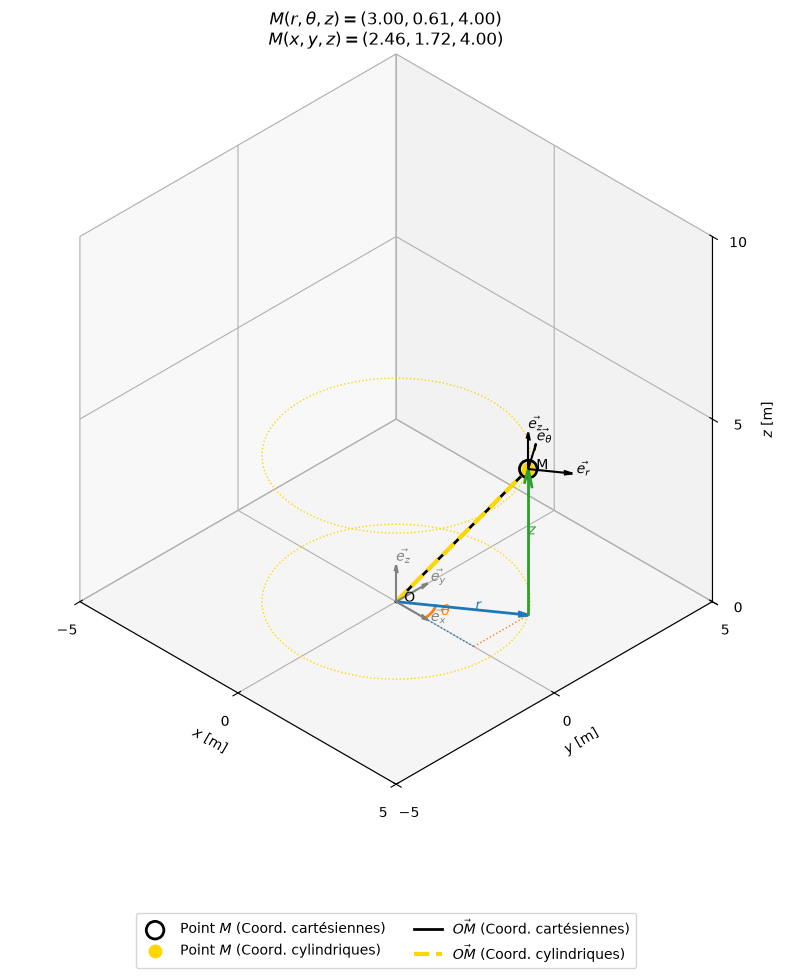

In [11]:
def plot_point_cylindrical(r, theta, z):
    """Trace un point M décrit par ses coordonnées cylindriques."""
    x, y, z_cart = cylindrical_to_cartesian(r, theta, z)

    fig, ax = plt.subplots(figsize=(12, 10),subplot_kw={"projection": "3d"})

    angle = np.linspace(0.0, 2.0 * np.pi, 100)

    # Cylindre de référence
    x_bot, y_bot, z_bot = cylindrical_to_cartesian(r, angle,np.zeros_like(angle))
    x_top, y_top, z_top = cylindrical_to_cartesian(r, angle,z * np.ones_like(angle))
    ax.plot(x_bot, y_bot, z_bot, linestyle=":", color="gold", linewidth=1)
    ax.plot(x_top, y_top, z_top, linestyle=":", color="gold", linewidth=1)

    # Repère cartésien
    x_r = r * np.cos(theta)
    y_r = r * np.sin(theta)
    z_r = z
    ax.plot([0, x_r], [0, 0], [0, 0],         linestyle=":", color="tab:blue",  linewidth=1.0)
    ax.plot([x_r, x_r], [0, y_r], [0, 0],     linestyle=":", color="tab:orange",linewidth=1.0)
    ax.plot([x_r, x_r], [y_r, y_r], [0, z_r], linestyle=":", color="tab:green", linewidth=1.0)

    # Point M
    ax.scatter(x_r, y_r,  z_r, color='black',facecolors="none", s=160, linewidths=2, label=r"Point $M$ (Coord. cartésiennes)")
    ax.scatter(x, y, z_cart,   color="gold", s=80, label=r"Point $M$ (Coord. cylindriques)")

    # Vecteur position OM
    ax.plot([0, x_r], [0, y_r], [0, z_r], linestyle="-",  linewidth=2, color="black", label=r"$\vec{OM}$ (Coord. cartésiennes)")
    ax.plot([0, x], [0, y], [0, z_cart] , linestyle="--", linewidth=3, color="gold",  label=r"$\vec{OM}$ (Coord. cylindriques)")

    # Composantes cylindriques
    ax.quiver(0, 0, 0, x, y, 0, color="tab:blue", arrow_length_ratio=0.08, linewidth=2)
    ax.quiver(x, y, 0, 0, 0, z_cart, color="tab:green", arrow_length_ratio=0.12, linewidth=2)
    ax.text(0.6 * x, 0.6 * y, 0, r"$r$", color="tab:blue")
    ax.text(x, y, 0.55 * z_cart, r"$z$", color="tab:green")

    # Angle theta dans le plan xy
    arc_radius = 0.3 * r
    angle_values = np.linspace(0.0, theta, 50)

    ax.plot( arc_radius * np.cos(angle_values), arc_radius * np.sin(angle_values), np.zeros_like(angle_values), color="tab:orange", linewidth=2)
    theta_label_angle = theta / 2 if theta != 0 else 0.12
    ax.text( 0.38 * r * np.cos(theta_label_angle), 0.38 * r * np.sin(theta_label_angle), 0, r"$\theta$", color="tab:orange")

    # Étiquettes de texte
    ax.text(0, 0, 0, "  O")
    ax.text(x, y, z_cart, "  M")

    # Base cartésienne fixe à l'origine
    basis_length = 1.0
    label_length = 1.1 * basis_length
    ax.quiver(0, 0, 0, basis_length, 0, 0, color="grey", arrow_length_ratio=0.2)
    ax.quiver(0, 0, 0, 0, basis_length, 0, color="grey", arrow_length_ratio=0.2)
    ax.quiver(0, 0, 0, 0, 0, basis_length, color="grey", arrow_length_ratio=0.2)
    ax.text(label_length, 0, 0, r"$\vec{e_x}$", color="grey")
    ax.text(0, label_length, 0, r"$\vec{e_y}$", color="grey")
    ax.text(0, 0, label_length, r"$\vec{e_z}$", color="grey")

    # Base cylindrique mobile en M
    e_r = np.array([np.cos(theta), np.sin(theta), 0.0])
    e_t= np.array([-np.sin(theta), np.cos(theta), 0.0])
    e_z = np.array([0.0, 0.0, 1.0])
    ax.quiver(x, y, z_cart, *(basis_length * e_r), color="black", arrow_length_ratio=0.2)
    ax.quiver(x, y, z_cart, *(basis_length * e_t), color="black", arrow_length_ratio=0.2)
    ax.quiver(x, y, z_cart, *(basis_length * e_z), color="black", arrow_length_ratio=0.2)
    ax.text(*(np.array([x, y, z_cart]) + label_length * e_t), r"$\vec{e_\theta}$", color="black")
    ax.text(*(np.array([x, y, z_cart]) + label_length * e_r), r"$\vec{e_r}$", color="black")
    ax.text(*(np.array([x, y, z_cart]) + label_length * e_z), r"$\vec{e_z}$", color="black")


    # Limites des axes
    LIMIT_XY = 5.0
    LIMIT_Z = 10.0
    ax.set_xlim(-LIMIT_XY, LIMIT_XY)
    ax.set_ylim(-LIMIT_XY, LIMIT_XY)
    ax.set_zlim(0, LIMIT_Z)
    ax.set_xticks([-5, 0, 5])
    ax.set_yticks([-5, 0, 5])
    ax.set_zticks([0, 5, 10])

    # Projection 3D
    ax.set_box_aspect((2 * LIMIT_XY, 2 * LIMIT_XY, LIMIT_Z))
    ax.set_proj_type("ortho")
    ax.view_init(elev=35.264, azim=-45)

    ax.set_xlabel(r"$x$ [m]")
    ax.set_ylabel(r"$y$ [m]")
    ax.set_zlabel(r"$z$ [m]")
    ax.set_title(
        rf"$M(r,\theta,z)=({r:.2f}, {theta:.2f}, {z:.2f})$"
        "\n"
        rf"$M(x,y,z)=({x:.2f}, {y:.2f}, {z_cart:.2f})$"
    )

    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.02), ncol=2)
    fig.tight_layout(rect=(0, 0.16, 1, 1))
    plt.show()
    plt.close(fig)

plot_point_cylindrical(r, theta, z)

In [12]:
# Version interactive
def plot_point_cylindrical_degrees(r, theta_degrees, z):
    plot_point_cylindrical(r, np.radians(theta_degrees), z)

interact(
    plot_point_cylindrical_degrees,
    r=FloatSlider(value=3.0, min=1.0, max=5.0, step=0.1),
    theta_degrees=FloatSlider(value=35.0, min=0.0, max=360.0, step=5.0),
    z=FloatSlider(value=4.0, min=0, max=10.0, step=0.1),
);

interactive(children=(FloatSlider(value=3.0, description='r', max=5.0, min=1.0), FloatSlider(value=35.0, descr…

:::{admonition} 🔍 Exploration
:class: tip

1. Le point physique change-t-il lorsque l'on passe de $(r,\theta,z)$ à
   $(x,y,z)$ ?
2. Quelle est l'influence de $r$ sur la position du point $M$ ?
3. Que se passe-t-il lorsque $\theta$ varie tandis que $r$ et $z$ restent
   constants ?
4. Quelle composante reste inchangée lors du passage aux coordonnées
   cartésiennes ?
:::

:::{admonition} Réponses
:class: note

1. Non. Seule sa description mathématique change.
2. Le paramètre $r$ fixe la distance du point à l'axe $Oz$.
3. Le point tourne autour de l'axe $Oz$ sur un cercle de rayon $r$ situé à la
   hauteur $z$.
4. La composante verticale reste inchangée : $z_{\mathrm{cart}}=z$.
:::

:::{important}
Pour afficher la version interactive, ouvrez le **Notebook enseignant** en
local ou ouvrez ce notebook dans Google Colab.
:::

## 5. Bilan

Ce TP a permis de représenter un même point matériel dans les bases
cartésienne et cylindrique, puis de relier ces deux descriptions.

À la suite de ce TP, vous devez être capable de répondre aux questions
suivantes :

1. Quelle est la différence entre un point matériel et ses coordonnées ?
2. Pourquoi un changement de coordonnées ne modifie-t-il pas le point physique ?
3. Dans quels types de mouvements les coordonnées cylindriques sont-elles plus
   naturelles que les coordonnées cartésiennes ?

:::{admonition} À retenir
:class: note

- Les coordonnées ne sont pas le point : elles décrivent sa position dans un
  système de coordonnées donné.
- Le point matériel $M$ reste le même lorsque sa description change.
- La projection d'un vecteur sur un axe s'obtient par produit scalaire avec
  le vecteur de base correspondant.
- La base cartésienne est fixe, tandis que la base polaire tourne avec
  l'angle $\theta$.
- Le même vecteur position s'écrit dans les deux bases :

$$
\boxed{
\overrightarrow{OM}
= r\,\overrightarrow{e_r} + z\,\overrightarrow{e_z}
= x\,\overrightarrow{e_x} + y\,\overrightarrow{e_y}
+ z\,\overrightarrow{e_z}
}
$$
:::

:::{admonition} Compétences acquises
:class: note

À l'issue de ce TP, vous devez être capable de :

- distinguer un point matériel, ses coordonnées et la base utilisée ;
- calculer les projections d'un vecteur position par produit scalaire avec
  les vecteurs de base ;
- exprimer les vecteurs de la base polaire dans la base cartésienne ;
- convertir des coordonnées cylindriques en coordonnées cartésiennes ;
- interpréter graphiquement les composantes du vecteur position.
:::

**À revoir avec les profs.**

## Pour aller plus loin : coordonnées sphériques

En vous appuyant sur l'exemple du passage des coordonnées cylindriques aux
coordonnées cartésiennes, appliquez le même principe afin de représenter
graphiquement le passage des coordonnées sphériques aux coordonnées
cartésiennes.

On définit un point matériel $M$ par ses coordonnées sphériques
$(\rho, \theta, \varphi)$. Nous utilisons ici la convention des
physiciens, la plus courante en France :

- $\rho$ est la distance de l'origine $O$ au point $M$ ;
- $\theta$ est l'angle polaire (ou colatitude), mesuré depuis l'axe $Oz$ ;
- $\varphi$ est l'angle azimutal, mesuré dans le plan $xy$ à partir de
  l'axe $Ox$.

On considère les valeurs suivantes :

$$
\rho = 4~\mathrm{m}, \qquad
\theta = 35^\circ, \qquad
\varphi = 50^\circ.
$$

Dans la base sphérique
$(\overrightarrow{e_\rho}, \overrightarrow{e_\theta},
\overrightarrow{e_\varphi})$, le vecteur position est donné par :

$$
\overrightarrow{OM} = \rho\,\overrightarrow{e_\rho}.
$$

:::{admonition} Travail demandé — Mise en application
:class: tip

1. Comment le vecteur $\overrightarrow{OM}$ s'exprime-t-il dans la base
   cartésienne
   $(\overrightarrow{e_x}, \overrightarrow{e_y}, \overrightarrow{e_z})$ ?
2. Définissez une fonction `spherical_to_cartesian(rho, theta, phi)` qui
   renvoie les coordonnées cartésiennes $(x, y, z)$ du point $M$.
3. Représentez graphiquement en 3D le point $M$, le vecteur
   $\overrightarrow{OM}$ et les relations entre ses coordonnées sphériques
   et cartésiennes.
:::